In [3]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import random

# Set seeds for reproducibility
random.seed(42)
np.random.seed(42)

In [4]:
def epsilon_greedy_policy(Q, state, epsilon, n_actions):
    if random.random() < epsilon:
        return random.randint(0, n_actions - 1)
    
    max_q = np.max(Q[state])
    actions = np.where(Q[state] == max_q)[0]
    return np.random.choice(actions)

In [5]:

# EXPERIMENT 1: TD(0) Prediction
def td0_prediction(env, episodes, gamma=0.99):
    V = defaultdict(float)
    visit_counts = defaultdict(int)
    n_actions = env.action_space.n
    
    for _ in range(episodes):
        state, _ = env.reset(seed=42 + _)
        
        while True:
            action = env.action_space.sample()
            next_state, reward, terminated, truncated, _ = env.step(action)
            
            visit_counts[state] += 1
            
            td_target = reward + gamma * V[next_state] if not terminated else reward
            alpha = 0.1
            V[state] += alpha * (td_target - V[state])
            state = next_state
            
            if terminated or truncated:
                break
                
    return V, visit_counts

In [6]:
def plot_value_function(V, env, visits, passenger=0, destination=0, title="Value Function"):
    grid = np.zeros((5, 5))
    
    for row in range(5):
        for col in range(5):
            state = env.unwrapped.encode(row, col, passenger, destination)
            grid[row, col] = V[state] if visits[state] > 0 else 0
    
    plt.figure(figsize=(6, 6))
    plt.imshow(grid, cmap="coolwarm")
    plt.colorbar()
    plt.title(title)
    plt.tight_layout()
    plt.show()

In [7]:

# EXPERIMENT 2: SARSA vs. Q-Learning
def sarsa(env, episodes, alpha=0.5, gamma=0.99, epsilon=0.1):
    """On-policy SARSA Control."""
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    stats = {'rewards': [], 'steps': []}
    
    for _ in range(episodes):
        state, _ = env.reset(seed=42 + _)
        action = epsilon_greedy_policy(Q, state, epsilon, env.action_space.n)
        total_reward = 0
        step_count = 0
        
        while True:
            next_state, reward, terminated, truncated, _ = env.step(action)
            next_action = epsilon_greedy_policy(Q, next_state, epsilon, env.action_space.n)
            
            td_target = reward + gamma * Q[next_state][next_action] if not terminated else reward
            Q[state][action] += alpha * (td_target - Q[state][action])
            
            total_reward += reward
            step_count += 1
            state, action = next_state, next_action
            
            if terminated or truncated: break
        stats['rewards'].append(total_reward)
        stats['steps'].append(step_count)
    return Q, stats

def q_learning(env, episodes, alpha=0.5, gamma=0.99, epsilon=0.1):
    """Off-policy Q-Learning Control."""
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    stats = {'rewards': [], 'steps': []}
    
    for _ in range(episodes):
        state, _ = env.reset(seed=42 + _)
        total_reward = 0
        step_count = 0
        
        while True:
            action = epsilon_greedy_policy(Q, state, epsilon, env.action_space.n)
            next_state, reward, terminated, truncated, _ = env.step(action)
            
            max_q = np.max(Q[next_state])
            actions = np.where(Q[next_state] == max_q)[0]
            best_next_action = np.random.choice(actions)
            td_target = reward + gamma * Q[next_state][best_next_action] if not terminated else reward
            Q[state][action] += alpha * (td_target - Q[state][action])
            
            total_reward += reward
            step_count += 1
            state = next_state
            
            if terminated or truncated: break
        stats['rewards'].append(total_reward)
        stats['steps'].append(step_count)
    return Q, stats

In [8]:

# EXPERIMENT 4: n-Step SARSA

def n_step_sarsa(env, n, episodes, alpha=0.5, gamma=0.99, epsilon=0.1):
    """n-step SARSA (Sutton & Barto Section 7.2)."""
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    rewards_per_episode = []
    
    for _ in range(episodes):
        state, _ = env.reset(seed=42 + _)
        action = epsilon_greedy_policy(Q, state, epsilon, env.action_space.n)
        
        states, actions, rewards = [state], [action], [0]
        T = float('inf')
        t = 0
        total_reward = 0
        
        while True:
            if t < T:
                next_state, reward, terminated, truncated, _ = env.step(actions[t])
                states.append(next_state)
                rewards.append(reward)
                total_reward += reward
                if terminated or truncated:
                    T = t + 1
                else:
                    actions.append(epsilon_greedy_policy(Q, next_state, epsilon, env.action_space.n))
            
            tau = t - n + 1
            if tau >= 0:
                G = 0
                for i in range(tau + 1, min(tau + n, T) + 1):
                    G += (gamma ** (i - tau - 1)) * rewards[i]
                if tau + n < T:
                    G += gamma**n * Q[states[tau + n]][actions[tau + n]]
                
                Q[states[tau]][actions[tau]] += alpha * (G - Q[states[tau]][actions[tau]])
                
            if tau == T - 1: break
            t += 1
        rewards_per_episode.append(total_reward)
    return Q, rewards_per_episode

In [9]:

# VISUALIZATION UTILITIES
def moving_average(data, window=500):
    if len(data) < window:
        return data
    return np.convolve(data, np.ones(window)/window, mode='valid')

def plot_learning_curves(stats_dict, title, filename):
    plt.figure(figsize=(10, 5))
    for label, data in stats_dict.items():
        plt.plot(moving_average(data), label=label)
    plt.title(title)
    plt.xlabel("Episodes")
    plt.ylabel("Smoothed Reward")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [10]:
def plot_policy(Q, env, passenger=4, destination=0, title="Policy"):
    action_symbols = ['↓', '↑', '→', '←', 'P', 'D']
    
    plt.figure(figsize=(7, 7))
    plt.imshow(np.ones((5, 5)), cmap='Greys', vmin=0, vmax=1)

    for row in range(5):
        for col in range(5):
            state = env.unwrapped.encode(row, col, passenger, destination)
            if state in Q and np.any(Q[state] != 0):
                best_action = np.argmax(Q[state])
            else:
                best_action = np.random.randint(env.action_space.n)
            
            plt.text(col, row, action_symbols[best_action], 
                     ha='center', va='center', fontsize=20, color='blue', fontweight='bold')

    plt.title(title, fontsize=14)
    plt.xticks(np.arange(5))
    plt.yticks(np.arange(5))
    plt.grid(True, which='both', color='gray', linestyle='-', linewidth=0.5)
    plt.show()

Sample state chosen: 386
Visits: 108608
V after 10k: -364.9965
V after 200k: -376.1347


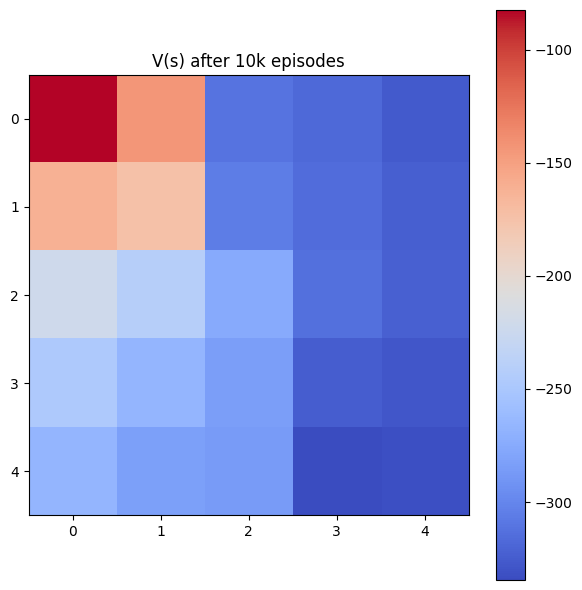

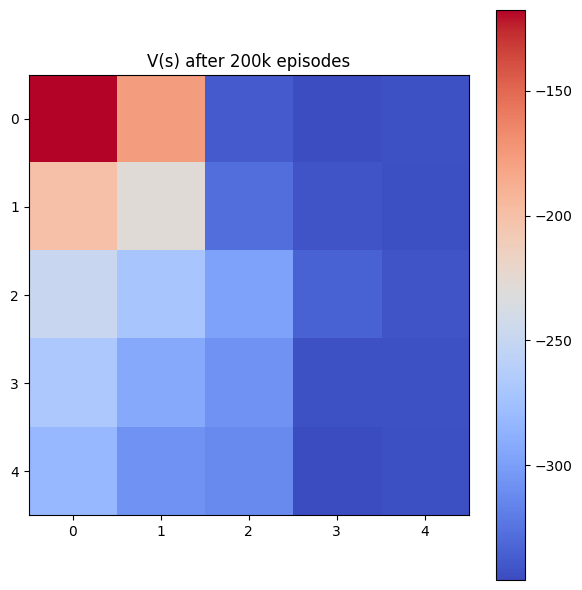

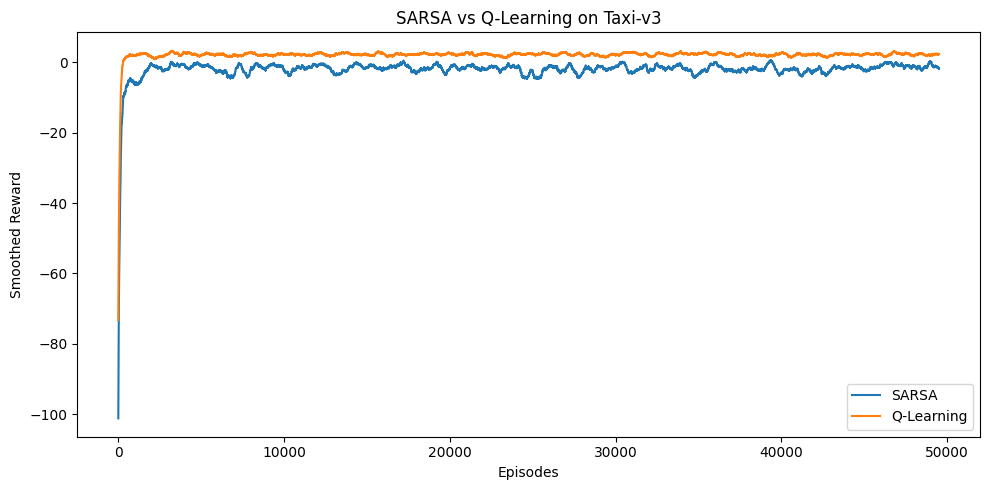

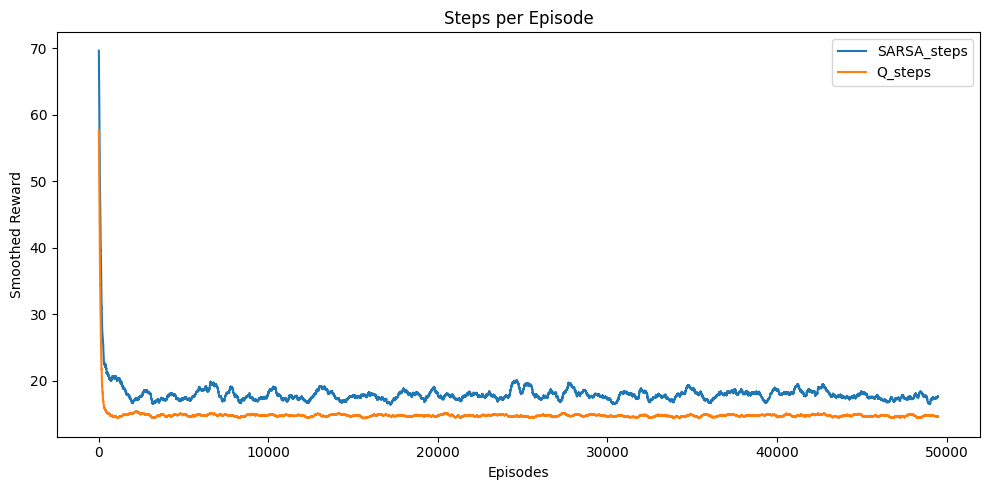

In [11]:
env = gym.make("Taxi-v3")

v_10k, visits_10k = td0_prediction(env, 10000)
v_200k, visits_200k = td0_prediction(env, 200000)

visited_states = [s for s in visits_200k if visits_200k[s] > 0]
sample_state = visited_states[0]

print(f"Sample state chosen: {sample_state}")
print(f"Visits: {visits_200k[sample_state]}")
print(f"V after 10k: {v_10k[sample_state]:.4f}")
print(f"V after 200k: {v_200k[sample_state]:.4f}")

plot_value_function(v_10k, env, visits_10k, passenger=4, destination=0, title="V(s) after 10k episodes")
plot_value_function(v_200k, env, visits_200k, passenger=4, destination=0, title="V(s) after 200k episodes")

q_sarsa, stats_sarsa = sarsa(env, 50000)
q_qlearn, stats_qlearn = q_learning(env, 50000)

plot_learning_curves({"SARSA": stats_sarsa['rewards'], "Q-Learning": stats_qlearn['rewards'],}, 
                     "SARSA vs Q-Learning on Taxi-v3", "sarsa_vs_q.png")

plot_learning_curves(
    {"SARSA_steps": stats_sarsa['steps'], "Q_steps": stats_qlearn['steps']},
    "Steps per Episode",
    "steps_plot.png"
)

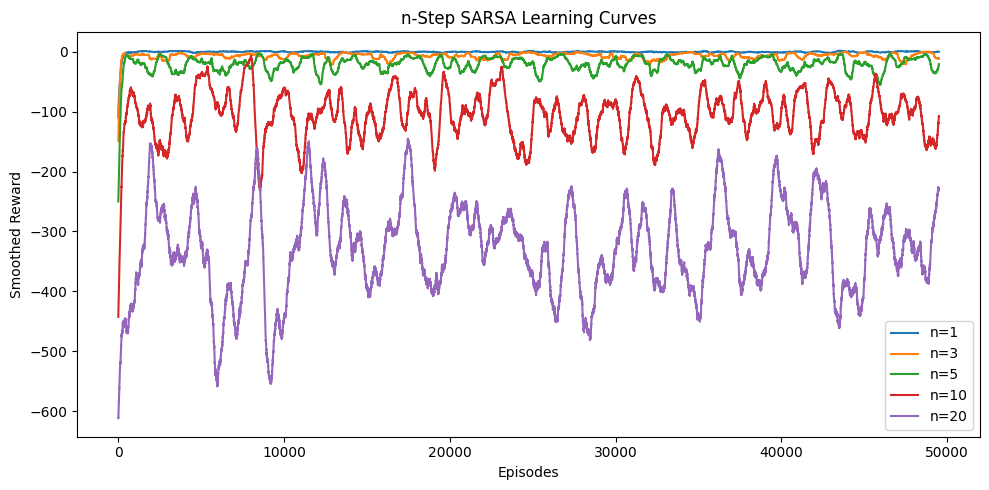

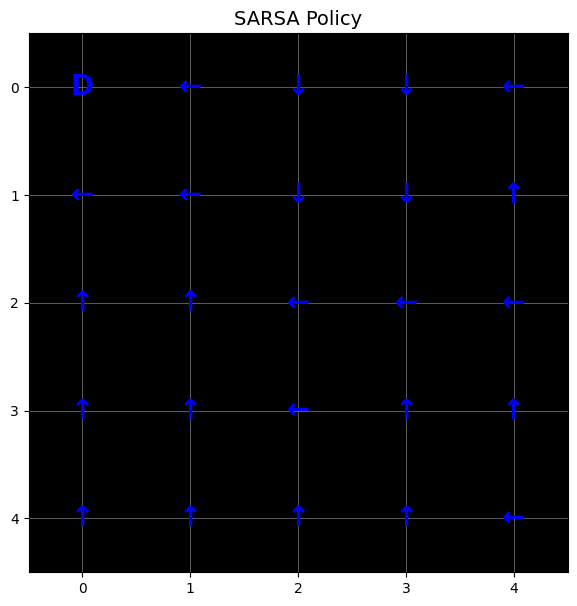

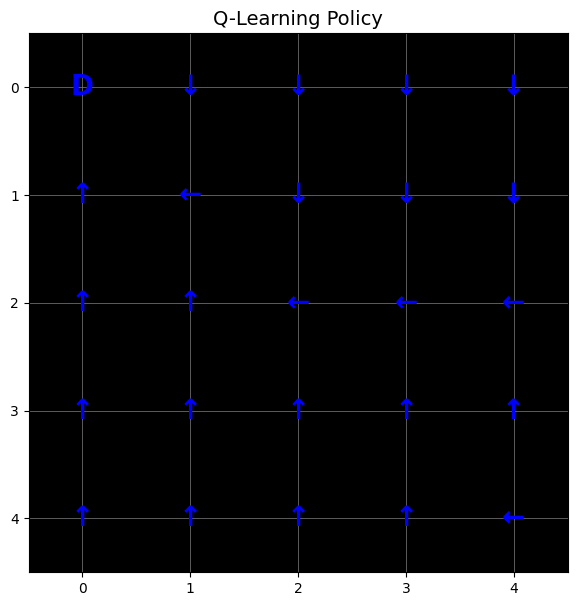

In [12]:
n_results = {}
for n in [1, 3, 5, 10, 20]:
    _, rewards = n_step_sarsa(env, n, 50000, alpha=0.4)
    n_results[f"n={n}"] = rewards

plot_learning_curves(n_results, "n-Step SARSA Learning Curves", "n_step_sarsa.png")

plot_policy(q_sarsa, env, title="SARSA Policy")
plot_policy(q_qlearn, env, title="Q-Learning Policy")

In [13]:
def run_final_hyperparameter_sweeps(env, episodes=30000):
    alphas = [0.1, 0.3, 0.5, 0.9]
    alpha_results = {}
    for a in alphas:
        print(f"Running Alpha={a}...")
        _, stats = q_learning(env, episodes, alpha=a, epsilon=0.1, gamma=0.99)
        alpha_results[f"alpha={a}"] = stats['rewards']
        mean_reward = np.mean(stats['rewards'][-5000:])
        print(f"alpha={a} → mean reward (last 5k): {mean_reward}")
    plot_learning_curves(alpha_results, "Experiment 3: Impact of Learning Rate (alpha)", "alpha_sweep.png")
    means = [np.mean(alpha_results[f"alpha={a}"][-5000:]) for a in alphas]

    plt.figure()
    plt.plot(alphas, means, marker='o')
    plt.xlabel("Alpha")
    plt.ylabel("Mean Reward (last 5k)")
    plt.title("Alpha vs Performance")
    plt.show()

    gammas = [0.8, 0.9, 0.95, 0.99]
    gamma_results = {}
    for g in gammas:
        print(f"Running Gamma={g}...")
        _, stats = q_learning(env, episodes, alpha=0.5, epsilon=0.1, gamma=g)
        gamma_results[f"gamma={g}"] = stats['rewards']
        mean_reward = np.mean(stats['rewards'][-5000:])
        print(f"gamma={g} → mean reward (last 5k): {mean_reward}")
    plot_learning_curves(gamma_results, "Experiment 3: Impact of Discount Factor (gamma)", "gamma_sweep.png")
    means = [np.mean(gamma_results[f"gamma={g}"][-5000:]) for g in gammas]

    plt.figure()
    plt.plot(gammas, means, marker='o')
    plt.xlabel("Gamma")
    plt.ylabel("Mean Reward (last 5k)")
    plt.title("Gamma vs Performance")
    plt.show()

    epsilons = [0.01, 0.05, 0.1, 0.3]
    eps_results = {}
    for e in epsilons:
        print(f"Running Epsilon={e}...")
        _, stats = q_learning(env, episodes, alpha=0.5, epsilon=e, gamma=0.99)
        eps_results[f"epsilon={e}"] = stats['rewards']
        mean_reward = np.mean(stats['rewards'][-5000:])
        print(f"epsilon={e} → mean reward (last 5k): {mean_reward}")
    plot_learning_curves(eps_results, "Experiment 3: Impact of Exploration (epsilon)", "epsilon_sweep.png")
    means = [np.mean(eps_results[f"epsilon={e}"][-5000:]) for e in epsilons]

    plt.figure()
    plt.plot(epsilons, means, marker='o')
    plt.xlabel("Epsilon")
    plt.ylabel("Mean Reward (last 5k)")
    plt.title("Epsilon vs Performance")
    plt.show()

Running Alpha=0.1...
alpha=0.1 → mean reward (last 5k): 2.2602
Running Alpha=0.3...
alpha=0.3 → mean reward (last 5k): 2.3996
Running Alpha=0.5...
alpha=0.5 → mean reward (last 5k): 2.2794
Running Alpha=0.9...
alpha=0.9 → mean reward (last 5k): 2.2312


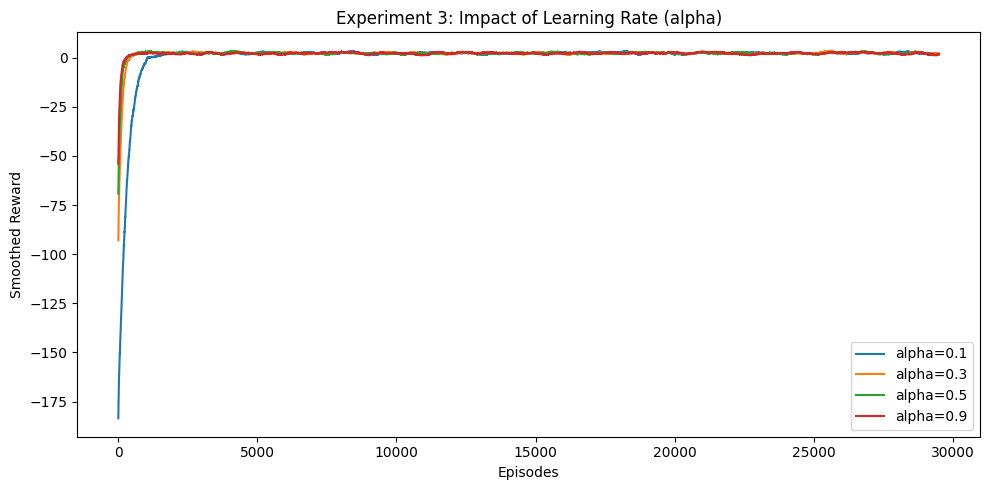

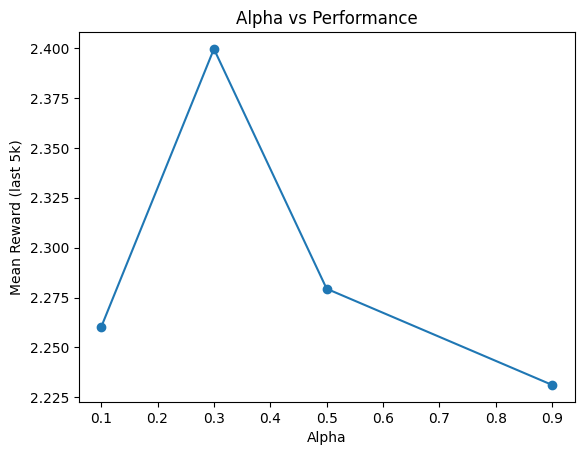

Running Gamma=0.8...
gamma=0.8 → mean reward (last 5k): 2.2804
Running Gamma=0.9...
gamma=0.9 → mean reward (last 5k): 2.2196
Running Gamma=0.95...
gamma=0.95 → mean reward (last 5k): 2.4132
Running Gamma=0.99...
gamma=0.99 → mean reward (last 5k): 2.23


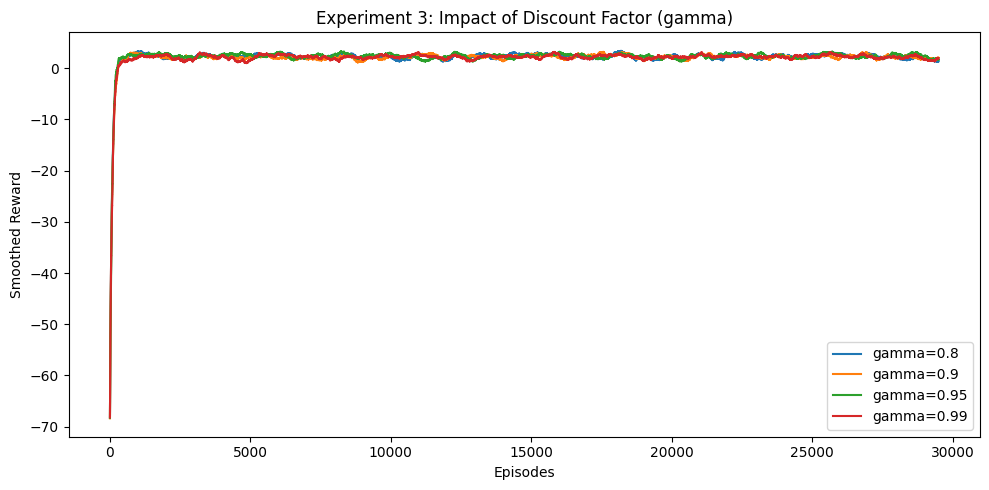

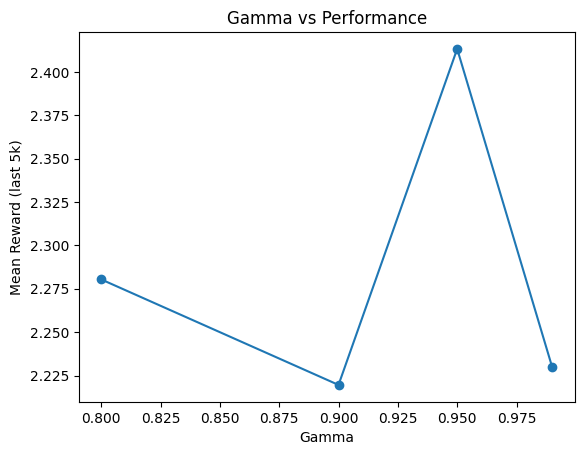

Running Epsilon=0.01...
epsilon=0.01 → mean reward (last 5k): 7.32
Running Epsilon=0.05...
epsilon=0.05 → mean reward (last 5k): 5.2644
Running Epsilon=0.1...
epsilon=0.1 → mean reward (last 5k): 2.329
Running Epsilon=0.3...
epsilon=0.3 → mean reward (last 5k): -14.377


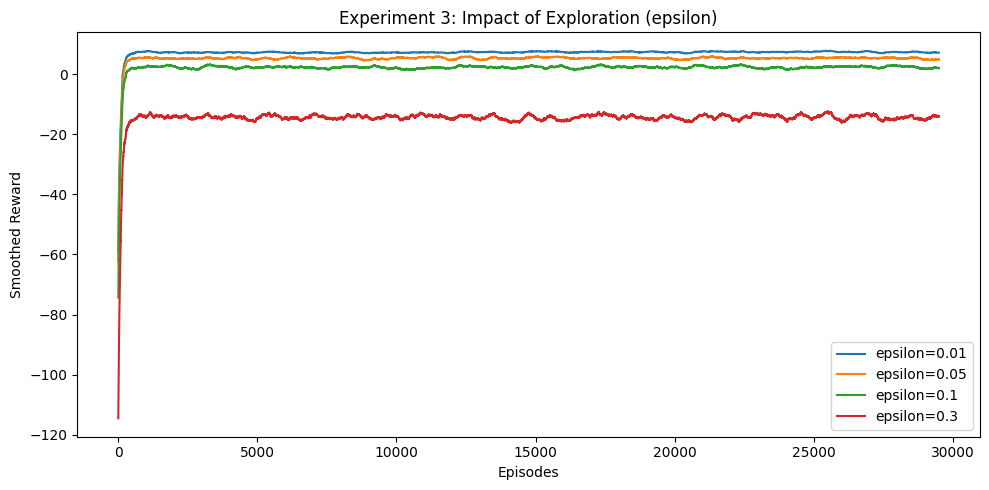

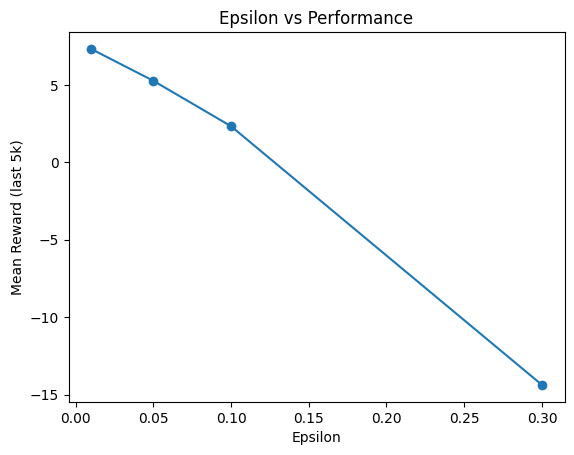

In [14]:
run_final_hyperparameter_sweeps(env)